# Introduction to Machine Learning

Project description

## Data Loading and Exploration

- Import necessary libraries (e.g., pandas, numpy, matplotlib, seaborn, sklearn).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve, roc_curve, roc_auc_score
from joblib import dump

- Load the dataset from a CSV file or an online source.

In [2]:
df = pd.read_csv("Churn Modeling.csv")

- Display basic dataset statistics (e.g., df.info(), df.describe()).

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


- Handle missing values, if any, and check for inconsistencies.

In [6]:
'''
Check for inconsistencies and missing values
'''
missing_values = df.isnull().sum()
problemId = df['CustomerId'].duplicated().sum()

print(missing_values)
print(problemId)
print("No inconsistencies and no missing values")

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
0
No inconsistencies and no missing values


## Data Preprocessing

- Implement data cleaning (removing duplicates, handling missing values, addressing outliers).

In [7]:
'''Clean data'''
'''There is nothing to clean, but I will write some code that could have been useful if there were something to clean'''

'''
# Removing duplicates :
df = df.drop_duplicates()

# For the missing values :
## You can drop the missing values
df = df.dropna()

## Replace with the mean
missing_values = df.isnull().sum()
columns_with_missing_values = missing_values[missing_values > 0].index
for c in columns_with_missing_values:
    df[c] = df[c].fillna(df[c].mean())

## Replace with the median
missing_values = df.isnull().sum()
columns_with_missing_values = missing_values[missing_values > 0].index
for c in columns_with_missing_values:
    df[c] = df[c].fillna(df[c].median())

## Replace with the mean based on their gender (for example)
missing_values = df.isnull().sum()
columns_with_missing_values = missing_values[missing_values > 0].index
for c in columns_with_missing_values:
    df_grouped = df.groupby('Gender')[c].mean()
    for gender in df_grouped.index:
        row = (df['Gender'] == gender) & (df[c].isnull())
        df.loc[row, c] = df_grouped[gender]


## Replace with the median based on their gender (for example)
missing_values = df.isnull().sum()
columns_with_missing_values = missing_values[missing_values > 0].index
for c in columns_with_missing_values:
    df_grouped = df.groupby('Gender')[c].median()
    for gender in df_grouped.index:
        row = (df['Gender'] == gender) & (df[c].isnull())
        df.loc[row, c] = df_grouped[gender]
'''

'''However, I can remove rows with outliers in the EstimatedSalary column'''
df_cleaned = df.copy()
salary_mean = df['EstimatedSalary'].mean()
salary_std = df['EstimatedSalary'].std()
df_cleaned['EstimatedSalary'] = np.where((df['EstimatedSalary'] - salary_mean).abs() > 3 * salary_std, salary_mean, df['EstimatedSalary'])

print("Number of row in EstimatedSalary column :", df_cleaned['EstimatedSalary'].count())
'''As you can see, it removed nothing (the dataset is perfect!!!)'''

'''I will drop the columns 'RowNumber', 'CustomerId' and 'Surname because they contain useless information'''
df_cleaned = df_cleaned.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

Number of row in EstimatedSalary column : 10000


- Perform feature scaling (standardization or normalization) where necessary.

In [8]:
'''Standardization and normalization'''
column_to_normalize = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

for c in column_to_normalize:
    minimum = df_cleaned[c].min()
    maximum = df_cleaned[c].max()
    df_cleaned[c] = (df_cleaned[c] - minimum) / maximum

- Encode categorical variables (one-hot encoding or label encoding).

In [9]:
'''one-hot encoding and label encoding'''

'''One-hot encoding version'''
one_hot_geography = pd.get_dummies(df_cleaned['Geography']).astype(int)
one_hot_gender = pd.get_dummies(df_cleaned['Gender']).astype(int)
df_encoded_one_hot = pd.concat([df_cleaned, one_hot_geography, one_hot_gender], axis=1)
df_encoded_one_hot = df_encoded_one_hot.drop(['Geography', 'Gender'], axis=1)


'''Label encoding version'''
df_encoded_label = df_cleaned.copy()
le = LabelEncoder()

df_encoded_label['Geography'] = le.fit_transform(df_cleaned['Geography'])
print("Geography Label Encoding Mapping:")
print(dict(zip(le.classes_, le.transform(le.classes_))))

df_encoded_label['Gender'] = le.fit_transform(df_cleaned['Gender'])
print("\nGender Label Encoding Mapping:")
print(dict(zip(le.classes_, le.transform(le.classes_))))


'''Print the dataframe'''
print("\nOne-hot encoded DataFrame columns:")
print(df_encoded_one_hot.columns.tolist())

print("\nSample of one-hot encoded data:")
print(df_encoded_one_hot.head(8))

print("\nLabel encoded DataFrame columns:")
print(df_encoded_label.columns.tolist())

print("\nSample of label encoded data:")
print(df_encoded_label.head(8))

Geography Label Encoding Mapping:
{'France': 0, 'Germany': 1, 'Spain': 2}

Gender Label Encoding Mapping:
{'Female': 0, 'Male': 1}

One-hot encoded DataFrame columns:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'France', 'Germany', 'Spain', 'Female', 'Male']

Sample of one-hot encoded data:
   CreditScore       Age  Tenure   Balance  NumOfProducts  HasCrCard  \
0     0.316471  0.260870     0.2  0.000000           0.00          1   
1     0.303529  0.250000     0.1  0.334031           0.00          0   
2     0.178824  0.260870     0.8  0.636357           0.50          1   
3     0.410588  0.228261     0.1  0.000000           0.25          0   
4     0.588235  0.271739     0.2  0.500246           0.00          1   
5     0.347059  0.282609     0.8  0.453394           0.25          1   
6     0.555294  0.347826     0.7  0.000000           0.25          1   
7     0.030588  0.119565     0.4  0.458540           0.

- Split the dataset into training and testing sets.

In [10]:
'''Split the dataset into training and testing sets'''

'''One-hot encoded version'''
X_one_hot = df_encoded_one_hot.drop('Exited', axis=1)
y_one_hot = df_encoded_one_hot['Exited']

X_train_one_hot, X_test_one_hot, y_train_one_hot, y_test_one_hot = train_test_split(
    X_one_hot, 
    y_one_hot, 
    test_size=0.2, 
    random_state = 42, 
    stratify = y_one_hot
)

'''Label encoded version'''
X_label = df_encoded_label.drop('Exited', axis=1)
y_label = df_encoded_label['Exited']

X_train_label, X_test_label, y_train_label, y_test_label = train_test_split(
    X_label, 
    y_label, 
    test_size=0.2, 
    random_state = 42, 
    stratify = y_label
)

## Model Selection & Training

- Define at least two machine learning models (e.g., logistic regression, decision trees, support vector machines, neural networks…etc.).
- Train models using the training dataset.
- Save trained models (e.g., using joblib or pickle).

In [11]:
def train_models(X_train, y_train, encoding_type):
    '''Define the learning machine models'''
    log_reg = LogisticRegression(max_iter=1000, random_state=42)
    gnb = GaussianNB()
    rf = RandomForestClassifier(random_state=42)
    
    '''Train models using the training dataset'''
    log_reg.fit(X_train, y_train)
    gnb.fit(X_train, y_train)
    rf.fit(X_train, y_train)
    
    '''Save trained models using joblib'''
    dump(log_reg, f'logistic_regression_{encoding_type}.joblib')
    dump(gnb, f'gaussian_naive_bayes_{encoding_type}.joblib')
    dump(rf, f'random_forest_{encoding_type}.joblib')
    
    return log_reg, gnb, rf

log_reg_one_hot, gnb_one_hot, rf_one_hot = train_models(
    X_train_one_hot,
    y_train_one_hot,
    'one_hot'
)

log_reg_label, gnb_label, rf_label = train_models(
    X_train_label,
    y_train_label,
    'label'
)

## Evaluation & Metrics Calculation

- Predict outcomes on the test dataset.

In [12]:
def predict_outcomes(models, X_test, y_test, encoding_type):
    L = []
    for model_name, model in models.items():
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)[:, 1]

        L.append({'Model name' : model_name,
                  'Model' : model,
                  'Encoding type' : encoding_type,
                  'Actual': y_test.values,
                  'Predicted': y_pred,
                  'Probability': y_pred_proba
                  })
    
    return L

one_hot_models = {
    'Logistic Regression': log_reg_one_hot,
    'Gaussian Naive Bayes': gnb_one_hot,
    'Random Forest': rf_one_hot
}

label_models = {
    'Logistic Regression': log_reg_label,
    'Gaussian Naive Bayes': gnb_label,
    'Random Forest': rf_label
}

one_hot_prediction = predict_outcomes(one_hot_models, X_test_one_hot, y_test_one_hot, 'One-Hot')
label_prediction = predict_outcomes(label_models, X_test_label, y_test_label, 'Label')

print(one_hot_prediction)
print(label_prediction)

[{'Model name': 'Logistic Regression', 'Model': LogisticRegression(max_iter=1000, random_state=42), 'Encoding type': 'One-Hot', 'Actual': array([0, 0, 0, ..., 1, 0, 0], dtype=int64), 'Predicted': array([0, 0, 0, ..., 1, 0, 0], dtype=int64), 'Probability': array([0.12081387, 0.28539017, 0.11573514, ..., 0.66455688, 0.13383978,
       0.14083272])}, {'Model name': 'Gaussian Naive Bayes', 'Model': GaussianNB(), 'Encoding type': 'One-Hot', 'Actual': array([0, 0, 0, ..., 1, 0, 0], dtype=int64), 'Predicted': array([0, 0, 0, ..., 1, 0, 0], dtype=int64), 'Probability': array([0.03683805, 0.3539671 , 0.07190651, ..., 0.86581611, 0.04451559,
       0.07332455])}, {'Model name': 'Random Forest', 'Model': RandomForestClassifier(random_state=42), 'Encoding type': 'One-Hot', 'Actual': array([0, 0, 0, ..., 1, 0, 0], dtype=int64), 'Predicted': array([0, 0, 0, ..., 1, 0, 0], dtype=int64), 'Probability': array([0.05, 0.06, 0.12, ..., 0.84, 0.  , 0.19])}]
[{'Model name': 'Logistic Regression', 'Model': L

- Compute performance metrics such as accuracy, precision, recall, F1-score for classification or RMSE, MAE for regression.

In [13]:
def calculate_metrics(predictions_list):
    L = []
    for pred_dict in predictions_list:
        metrics = {
            'Model': pred_dict['Model name'],
            'Encoding': pred_dict['Encoding type'],
            'Accuracy': accuracy_score(pred_dict['Actual'], pred_dict['Predicted']),
            'Precision': precision_score(pred_dict['Actual'], pred_dict['Predicted']),
            'Recall': recall_score(pred_dict['Actual'], pred_dict['Predicted']),
            'F1': f1_score(pred_dict['Actual'], pred_dict['Predicted'])
        }
        L.append(metrics)
    return pd.DataFrame(L)

metrics_one_hot = calculate_metrics(one_hot_prediction)
metrics_label = calculate_metrics(label_prediction)

all_metrics = pd.concat([metrics_one_hot, metrics_label])
print(all_metrics)

                  Model Encoding  Accuracy  Precision    Recall        F1
0   Logistic Regression  One-Hot    0.8100   0.613445  0.179361  0.277567
1  Gaussian Naive Bayes  One-Hot    0.8060   0.533101  0.375921  0.440922
2         Random Forest  One-Hot    0.8590   0.765957  0.442260  0.560748
0   Logistic Regression    Label    0.8055   0.602273  0.130221  0.214141
1  Gaussian Naive Bayes    Label    0.8290   0.755906  0.235872  0.359551
2         Random Forest    Label    0.8635   0.776860  0.461916  0.579353


- Generate a classification report and confusion matrix (if applicable).

In [14]:
predictions_list = one_hot_prediction + label_prediction
for pred_dict in predictions_list:
    print(f"Classification Report for {pred_dict['Model name']} ({pred_dict['Encoding type']} encoding):")
    print(classification_report(pred_dict['Actual'], pred_dict['Predicted']))
        
    cm = confusion_matrix(pred_dict['Actual'], pred_dict['Predicted'])
    print(f"Confusion Matrix for {pred_dict['Model name']} ({pred_dict['Encoding type']} encoding):")
    print(cm)
    print("")

Classification Report for Logistic Regression (One-Hot encoding):
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.61      0.18      0.28       407

    accuracy                           0.81      2000
   macro avg       0.72      0.58      0.58      2000
weighted avg       0.78      0.81      0.77      2000

Confusion Matrix for Logistic Regression (One-Hot encoding):
[[1547   46]
 [ 334   73]]

Classification Report for Gaussian Naive Bayes (One-Hot encoding):
              precision    recall  f1-score   support

           0       0.85      0.92      0.88      1593
           1       0.53      0.38      0.44       407

    accuracy                           0.81      2000
   macro avg       0.69      0.65      0.66      2000
weighted avg       0.79      0.81      0.79      2000

Confusion Matrix for Gaussian Naive Bayes (One-Hot encoding):
[[1459  134]
 [ 254  153]]

Classification Report for Random F

## Visualization & Results Interpretation

Plot relevant visualizations :

- Confusion matrix for classification tasks.

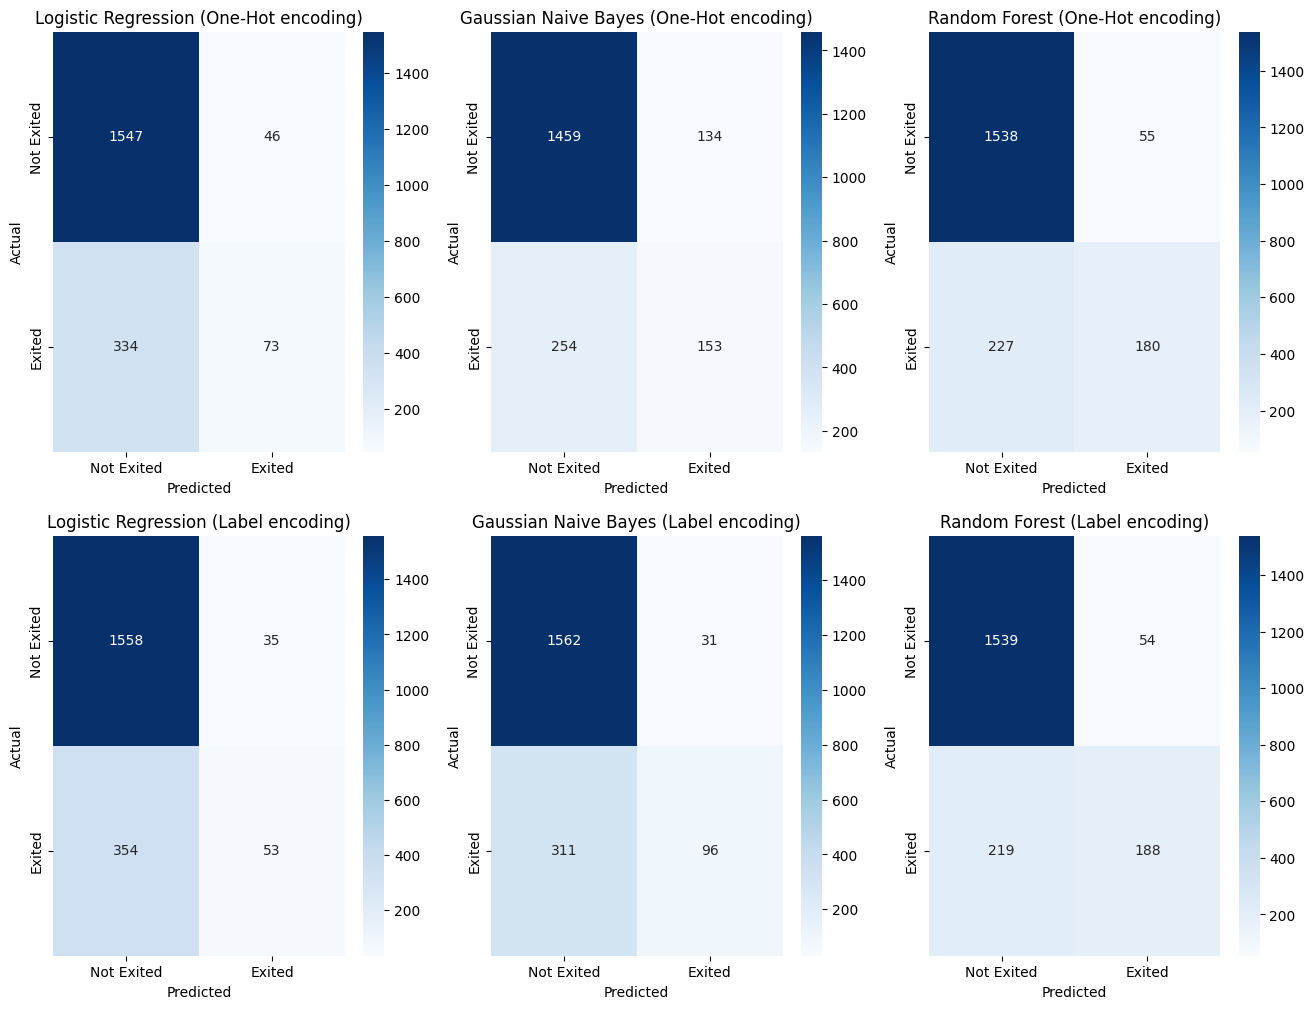

In [15]:
plt.figure(figsize=(16,12))
index = 1
for pred_dict in predictions_list:
    plt.subplot(2, 3, index)
    sns.heatmap(confusion_matrix(pred_dict['Actual'], pred_dict['Predicted']), 
                annot=True, fmt='d', cmap='Blues',
                xticklabels=['Not Exited', 'Exited'],
                yticklabels=['Not Exited', 'Exited'])
    plt.title(f"{pred_dict['Model name']} ({pred_dict['Encoding type']} encoding)")
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    index += 1

plt.show()

- ROC curves and precision-recall curves.

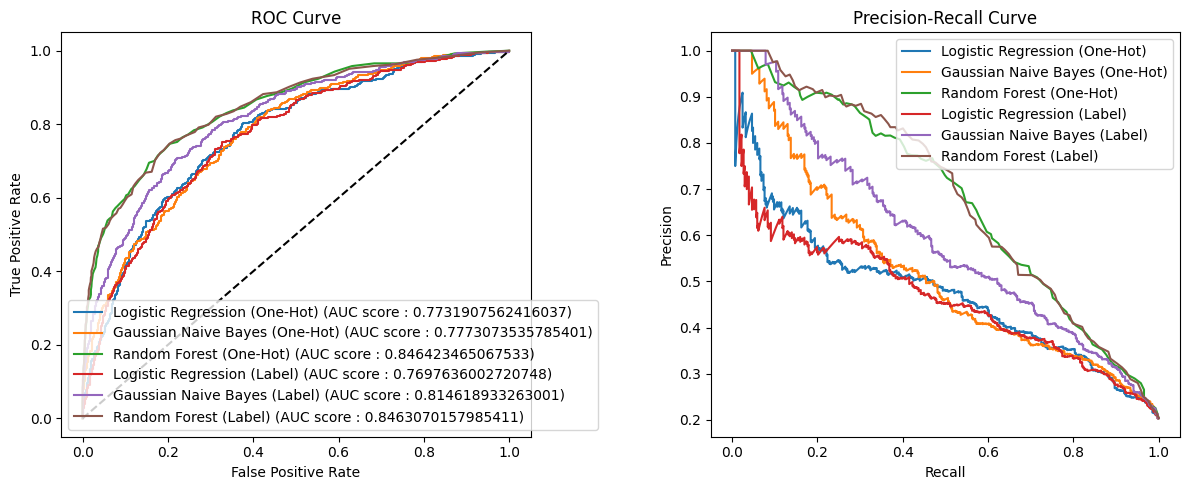

In [16]:
plt.figure(figsize=(12, 5))    
'''ROC Curve'''
plt.subplot(1, 2, 1)
for pred_dict in predictions_list:
    fpr, tpr, _ = roc_curve(pred_dict['Actual'], pred_dict['Probability'])
    plt.plot(fpr, tpr, label=f"{pred_dict['Model name']} ({pred_dict['Encoding type']}) (AUC score : {roc_auc_score(pred_dict['Actual'], pred_dict['Probability'])})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
    
'''Precision-Recall Curve'''
plt.subplot(1, 2, 2)
for pred_dict in predictions_list:
    precision, recall, _ = precision_recall_curve(pred_dict['Actual'], pred_dict['Probability'])
    plt.plot(recall, precision, label=f"{pred_dict['Model name']} ({pred_dict['Encoding type']})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()

plt.tight_layout()
plt.show()

- Residual plots for regression tasks.

In [17]:
'''No regression'''

'No regression'

- Feature importance charts.

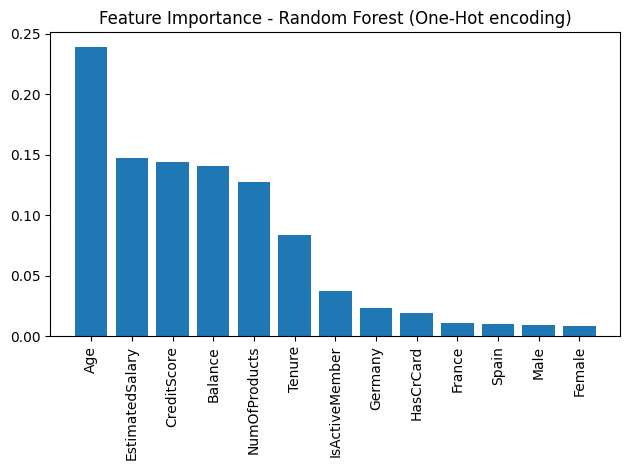

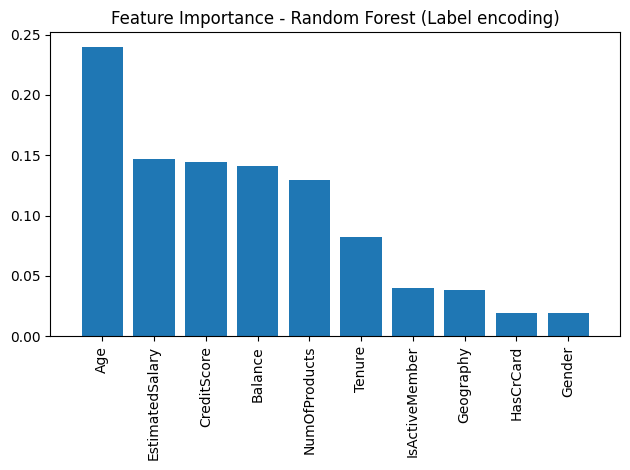

In [18]:
def plot_feature_importance(rf_model, X_train, encoding_type):
    importance = rf_model.feature_importances_
    features = X_train.columns
    indices = np.argsort(importance)[::-1]

    plt.title(f"Feature Importance - Random Forest ({encoding_type} encoding)")
    plt.bar(range(X_train.shape[1]), importance[indices], align="center")
    plt.xticks(range(X_train.shape[1]), features[indices], rotation=90)
    plt.xlim([-1, X_train.shape[1]])
    plt.tight_layout()
    plt.show()

plot_feature_importance(one_hot_models['Random Forest'], X_train_one_hot, 'One-Hot')
plot_feature_importance(label_models['Random Forest'], X_train_label, 'Label')